# Forecasting the S&P 500 Equity Premium with High-Dimensional Predictors

Five linear models, 132 monthly predictors, and recursive versus rolling forecasts.
The saved outputs show the completed study; rerunning requires the private input described in [data/README.md](data/README.md).


In [1]:
%matplotlib inline

import os
from pathlib import Path
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import (
    ElasticNet, ElasticNetCV, Lasso, LassoCV, LinearRegression, Ridge, RidgeCV,
)
from sklearn.preprocessing import StandardScaler

# 本地数据路径；环境变量可选。 / Local input; environment override is optional.
DATA_PATH = Path(os.getenv("EQUITY_PREMIUM_DATA", "data/monthly_data.csv"))
RESULTS = Path("results")
N_JOBS = 4  # 并行计算，不改变模型设定。 / Parallelism only; use 1 if needed.
WINDOW = 324
PCA_COMPONENTS = 14
MODEL_NAMES = ["OLS", "Ridge", "LASSO", "Elastic Net", "PCA-OLS"]
PLOT_MODELS = MODEL_NAMES[1:]  # OLS 留在表中，不画入图。 / OLS stays in tables only.
COLORS = ["#2674A5", "#C17D15", "#248B6A", "#9B5B9D"]

expected_columns = Path("data/columns.txt").read_text().splitlines()
predictor_names = [c for c in expected_columns if c not in ["date", "SPX", "TB3MS", "S&P div yield"]]
macro_names, technical_names = predictor_names[:-14], predictor_names[-14:]
assert len(macro_names) == 118 and len(technical_names) == 14

print("5 models | 132 predictors | 14 PCs | 324-month initial training window")


5 models | 132 predictors | 14 PCs | 324-month initial training window


## 1. Data and target

Predict month `t+1` premium using month `t` predictors. Premium is log-price return plus dividend yield/12, less TB3MS/12, in percentage points.


In [2]:
def load_data(path):
    """Validate the prepared input and align X[t] with the next-month premium."""
    if not path.exists():
        raise FileNotFoundError("Provide data/monthly_data.csv; see data/README.md.")
    raw = pd.read_csv(path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
    assert raw.columns.tolist() == expected_columns, "Column names/order must match data/columns.txt."
    assert raw.shape == (720, 136)
    assert raw.date.is_unique
    assert raw.date.dt.is_month_start.all(), "Dates must use YYYY-MM-01."
    expected_months = pd.Series(pd.period_range("1960-01", "2019-12", freq="M"))
    assert raw.date.dt.to_period("M").equals(expected_months)
    numeric = raw.drop(columns="date")
    assert numeric.notna().all().all() and np.isfinite(numeric).all().all()
    assert raw.SPX.gt(0).all() and raw[technical_names].isin([0, 1]).all().all()

    # 标签上移一月：本月因子预测下月溢价。 / Align this month's X with next month's y.
    premium = (
        np.log(raw.SPX).diff() * 100
        + raw["S&P div yield"] / 12
        - raw.TB3MS / 12
    )
    X = raw[predictor_names].iloc[:-1].reset_index(drop=True)
    y = premium.iloc[1:].reset_index(drop=True)
    target_month = raw.date.iloc[1:].reset_index(drop=True)
    assert len(X) == len(y) == 719 and y.notna().all()
    assert target_month.iloc[WINDOW] == pd.Timestamp("1987-02-01")
    return X, y, target_month

X, y, target_month = load_data(DATA_PATH)
display(pd.DataFrame([{
    "Data period": "1960-01 to 2019-12", "Macro / financial": len(macro_names),
    "Technical signals": len(technical_names), "Aligned pairs": len(y),
    "OOS months": len(y) - WINDOW,
}]))


,Data period,Macro / financial,Technical signals,Aligned pairs,OOS months
0,1960-01 to 2019-12,118,14,719,395


## 2. Models

OLS and regularized models scale the 118 macro inputs; binary signals pass through unchanged. PCA scales all 132 inputs and retains 14 PCs. Preprocessing uses each outer training window; ordinary CV and the study's 200-iteration settings are retained.


In [3]:
def fit_five(X_train, y_train, X_test):
    """Fit one training window; return predictions, fitted models and diagnostics."""
    # 只用训练窗估计标准化参数。 / Fit scaling on the training window only.
    macro_scaler = StandardScaler().fit(X_train[macro_names])
    train = X_train.to_numpy(copy=True)
    test = X_test.to_numpy(copy=True)
    train[:, :len(macro_names)] = macro_scaler.transform(X_train[macro_names])
    test[:, :len(macro_names)] = macro_scaler.transform(X_test[macro_names])

    fitted, info = {}, {}
    fitted["OLS"] = LinearRegression().fit(train, y_train)
    ridge_cv = RidgeCV(
        alphas=np.linspace(400, 1900, 50), scoring="neg_mean_absolute_error", cv=5,
    ).fit(train, y_train)
    fitted["Ridge"] = Ridge(alpha=ridge_cv.alpha_).fit(train, y_train)
    info["Ridge alpha"] = float(ridge_cv.alpha_)

    # 固定本研究的选参和迭代设置，并记录警告。 / Keep settings and count warnings.
    with warnings.catch_warnings(record=True) as cv_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        lasso_cv = LassoCV(max_iter=200, tol=0.01, cv=5).fit(train, y_train)
    with warnings.catch_warnings(record=True) as final_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted["LASSO"] = Lasso(alpha=lasso_cv.alpha_, max_iter=200).fit(train, y_train)
    info["LASSO alpha"] = float(lasso_cv.alpha_)
    info["LASSO nonzero"] = int(np.count_nonzero(fitted["LASSO"].coef_))
    info["LASSO CV warnings"] = sum(issubclass(w.category, ConvergenceWarning) for w in cv_warnings)
    info["LASSO final warnings"] = sum(issubclass(w.category, ConvergenceWarning) for w in final_warnings)
    info["LASSO final iterations"] = int(fitted["LASSO"].n_iter_)

    with warnings.catch_warnings(record=True) as cv_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        en_cv = ElasticNetCV(max_iter=200, cv=10, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9]).fit(train, y_train)
    with warnings.catch_warnings(record=True) as final_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted["Elastic Net"] = ElasticNet(
            alpha=en_cv.alpha_, l1_ratio=en_cv.l1_ratio_, max_iter=200,
        ).fit(train, y_train)
    info["EN alpha"] = float(en_cv.alpha_)
    info["EN l1_ratio"] = float(en_cv.l1_ratio_)
    info["EN nonzero"] = int(np.count_nonzero(fitted["Elastic Net"].coef_))
    info["EN CV warnings"] = sum(issubclass(w.category, ConvergenceWarning) for w in cv_warnings)
    info["EN final warnings"] = sum(issubclass(w.category, ConvergenceWarning) for w in final_warnings)
    info["EN final iterations"] = int(fitted["Elastic Net"].n_iter_)

    # 全部132个变量一起做PCA。 / Apply PCA to all 132 standardized predictors.
    pca_scaler = StandardScaler().fit(X_train)
    train_all, test_all = pca_scaler.transform(X_train), pca_scaler.transform(X_test)
    pca = PCA(n_components=PCA_COMPONENTS, svd_solver="full").fit(train_all)
    fitted["PCA-OLS"] = LinearRegression().fit(pca.transform(train_all), y_train)
    predictions = {
        name: float(model.predict(pca.transform(test_all) if name == "PCA-OLS" else test)[0])
        for name, model in fitted.items()
    }
    return predictions, fitted, info

display(pd.DataFrame({
    "Model": MODEL_NAMES,
    "Regression inputs": [132, 132, 132, 132, 14],
    "Parameter selection": [
        "None", "5-fold CV / MAE; alpha 400–1900",
        "5-fold CV / MSE", "10-fold CV / MSE; 5 L1 ratios", "14 PCs (fixed)",
    ],
}))


,Model,Regression inputs,Parameter selection
0,OLS,132,None
1,Ridge,132,5-fold CV / MAE; alpha 400–1900
2,LASSO,132,5-fold CV / MSE
3,Elastic Net,132,10-fold CV / MSE; 5 L1 ratios
4,PCA-OLS,14,14 PCs (fixed)


## 3. One-month-ahead forecasts

Recursive training expands; rolling training keeps 324 observations. Both use their training-window mean as the benchmark. Independent monthly fits run in parallel.


In [4]:
def forecast_one(kind, i):
    start = 0 if kind == "recursive" else i - WINDOW
    predictions, _, info = fit_five(X.iloc[start:i], y.iloc[start:i], X.iloc[[i]])
    return {
        "window": kind, "date": target_month.iloc[i], "actual": float(y.iloc[i]),
        "benchmark": float(y.iloc[start:i].mean()), **predictions, **info,
    }


# 每月重新估计；只显示窗口汇总，不显示逐月预测。 / Refit monthly; display summaries only.
frames = []
for kind in ["recursive", "rolling"]:
    rows = Parallel(n_jobs=N_JOBS)(
        delayed(forecast_one)(kind, i) for i in range(WINDOW, len(y))
    )
    frames.append(pd.DataFrame(rows))
    print(f"{kind.title()}: {len(rows)} forecast months completed")
forecasts = pd.concat(frames, ignore_index=True)
assert len(forecasts) == 790 and not forecasts.duplicated(["window", "date"]).any()
display(forecasts.groupby("window").agg(
    Forecasts=("date", "size"), First_target=("date", "min"), Last_target=("date", "max"),
))


Recursive: 395 forecast months completed


Rolling: 395 forecast months completed


,Forecasts,First_target,Last_target
window,,,
recursive,395,1987-02-01,2019-12-01
rolling,395,1987-02-01,2019-12-01


## 4. Forecast evaluation

MSFE is mean squared forecast error. OOS R² is `100 × (1 − model MSFE / benchmark MSFE)`; CSSED sums benchmark squared error minus model squared error. Positive OOS R² / CSSED favors the model.


In [5]:
def score_forecasts(forecasts):
    rows = []
    for kind, frame in forecasts.groupby("window"):
        assert len(frame) == 395
        periods = {
            "full": frame,
            "1987-2007": frame[frame.date < "2008-01-01"],
            "2008-2019": frame[frame.date >= "2008-01-01"],
        }
        assert len(periods["1987-2007"]) == 251 and len(periods["2008-2019"]) == 144
        for period, part in periods.items():
            base_se = (part.actual - part.benchmark) ** 2
            assert base_se.sum() > 0
            for name in MODEL_NAMES:
                model_se = (part.actual - part[name]) ** 2
                rows.append({
                    "window": kind, "period": period, "months": len(part), "model": name,
                    "oos_r2_pct": 100 * (1 - model_se.sum() / base_se.sum()),
                    "msfe": model_se.mean(), "cssed_final": (base_se - model_se).sum(),
                })
    return pd.DataFrame(rows)


def summarize_convergence(forecasts):
    rows = []
    for kind, frame in forecasts.groupby("window"):
        for name, prefix in [("LASSO", "LASSO"), ("Elastic Net", "EN")]:
            rows.append({
                "window": kind, "model": name, "forecasts": len(frame),
                "cv_convergence_warnings": int(frame[f"{prefix} CV warnings"].sum()),
                "final_convergence_warnings": int(frame[f"{prefix} final warnings"].sum()),
                "hit_iteration_limit": int(frame[f"{prefix} final iterations"].ge(200).sum()),
            })
    return pd.DataFrame(rows)

scores = score_forecasts(forecasts)
convergence = summarize_convergence(forecasts)
assert len(scores) == 30 and set(scores.model) == set(MODEL_NAMES)
benchmark_msfe = scores.msfe + scores.cssed_final / scores.months
assert np.allclose(scores.oos_r2_pct, 100 * (1 - scores.msfe / benchmark_msfe))
RESULTS.mkdir(exist_ok=True)
scores.to_csv(RESULTS / "forecast_scores.csv", index=False)

display(scores[scores.period == "full"][
    ["window", "model", "oos_r2_pct", "msfe", "cssed_final"]
].round(3))
warnings_total = convergence.groupby("model").final_convergence_warnings.sum()
print("Final-fit convergence warnings / 790 fits each:", warnings_total.to_dict())


,window,model,oos_r2_pct,msfe,cssed_final
0,recursive,OLS,-126.256,28.837,-6356.211
1,recursive,Ridge,2.224,12.462,111.982
2,recursive,LASSO,-3.683,13.215,-185.420
3,recursive,Elastic Net,-0.388,12.795,-19.544
4,recursive,PCA-OLS,-2.218,13.028,-111.656
15,rolling,OLS,-257.066,45.608,-12969.705
16,rolling,Ridge,2.485,12.455,125.397
17,rolling,LASSO,2.003,12.517,101.040
18,rolling,Elastic Net,-0.710,12.863,-35.808
19,rolling,PCA-OLS,-10.785,14.150,-544.131


Final-fit convergence warnings / 790 fits each: {'Elastic Net': 364, 'LASSO': 18}


In [6]:
# 按目标收益月划分2008年前后。 / Split by forecast target month.
print("Subperiod OOS R² (%)")
display(scores[scores.period != "full"].pivot(
    index="model", columns=["period", "window"], values="oos_r2_pct",
).reindex(MODEL_NAMES).round(2))


Subperiod OOS R² (%)


period,1987-2007,2008-2019,1987-2007,2008-2019
window,recursive,recursive,rolling,rolling
model,,,,
OLS,-92.87,-172.03,-116.86,-450.85
Ridge,1.32,3.47,0.37,5.41
LASSO,3.83,-13.98,2.77,0.94
Elastic Net,6.91,-10.40,3.40,-6.38
PCA-OLS,0.29,-5.66,-2.06,-22.84


## 5. Forecast-error patterns

OLS remains in the tables but is omitted from the figures. CSSED is an error comparison, not an investment-return curve.


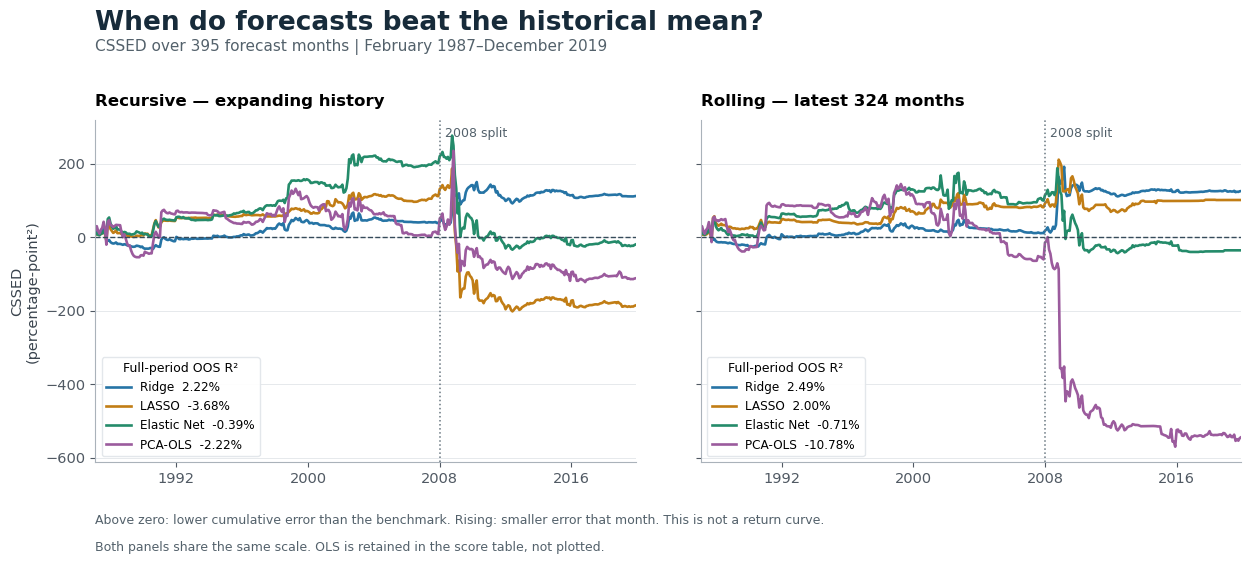

In [7]:
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#AAB2BA", "axes.labelcolor": "#39434D",
    "xtick.color": "#505963", "ytick.color": "#505963",
    "figure.facecolor": "white", "savefig.facecolor": "white",
})


def plot_cssed(forecasts, scores):
    fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.8), sharey=True)
    fig.subplots_adjust(left=0.085, right=0.98, top=0.79, bottom=0.20, wspace=0.12)
    fig.suptitle("When do forecasts beat the historical mean?", x=0.085, y=0.98,
                 ha="left", fontsize=19, fontweight="bold", color="#172B3A")
    fig.text(0.085, 0.91, "CSSED over 395 forecast months | February 1987–December 2019",
             color="#53616B", fontsize=11)
    for ax, kind in zip(axes, ["recursive", "rolling"]):
        frame = forecasts[forecasts.window == kind].sort_values("date")
        base_se = (frame.actual - frame.benchmark) ** 2
        full = scores[(scores.window == kind) & (scores.period == "full")].set_index("model")
        for name, color in zip(PLOT_MODELS, COLORS):
            cssed = (base_se - (frame.actual - frame[name]) ** 2).cumsum()
            ax.plot(frame.date, cssed, color=color, linewidth=1.9,
                    label=f"{name}  {full.loc[name, 'oos_r2_pct']:.2f}%")
        detail = "expanding history" if kind == "recursive" else "latest 324 months"
        ax.set_title(f"{kind.title()} — {detail}", loc="left", pad=10, fontsize=12, fontweight="bold")
        ax.axhline(0, color="#364B5A", linewidth=1, linestyle="--")
        ax.axvline(pd.Timestamp("2008-01-01"), color="#687680", linestyle=":", linewidth=1.1)
        ax.grid(axis="y", color="#E6E9EC", linewidth=0.7)
        ax.set_xlim(frame.date.min(), frame.date.max())
        ax.xaxis.set_major_locator(mdates.YearLocator(8))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.legend(loc="lower left", fontsize=8.7, title="Full-period OOS R²",
                  title_fontsize=9, framealpha=0.95, edgecolor="#E2E6EA")
        ax.text(pd.Timestamp("2008-05-01"), 0.98, "2008 split",
                transform=ax.get_xaxis_transform(), va="top", fontsize=9, color="#53616B")
        assert [label.split("  ")[0] for label in ax.get_legend_handles_labels()[1]] == PLOT_MODELS
    axes[0].set_ylabel("CSSED\n(percentage-point²)")
    fig.text(0.085, 0.093,
             "Above zero: lower cumulative error than the benchmark. Rising: smaller error that month. This is not a return curve.",
             fontsize=9, color="#53616B")
    fig.text(0.085, 0.047,
             "Both panels share the same scale. OLS is retained in the score table, not plotted.",
             fontsize=9, color="#53616B")
    fig.savefig(RESULTS / "cssed.png", dpi=160)
    plt.show()

plot_cssed(forecasts, scores)


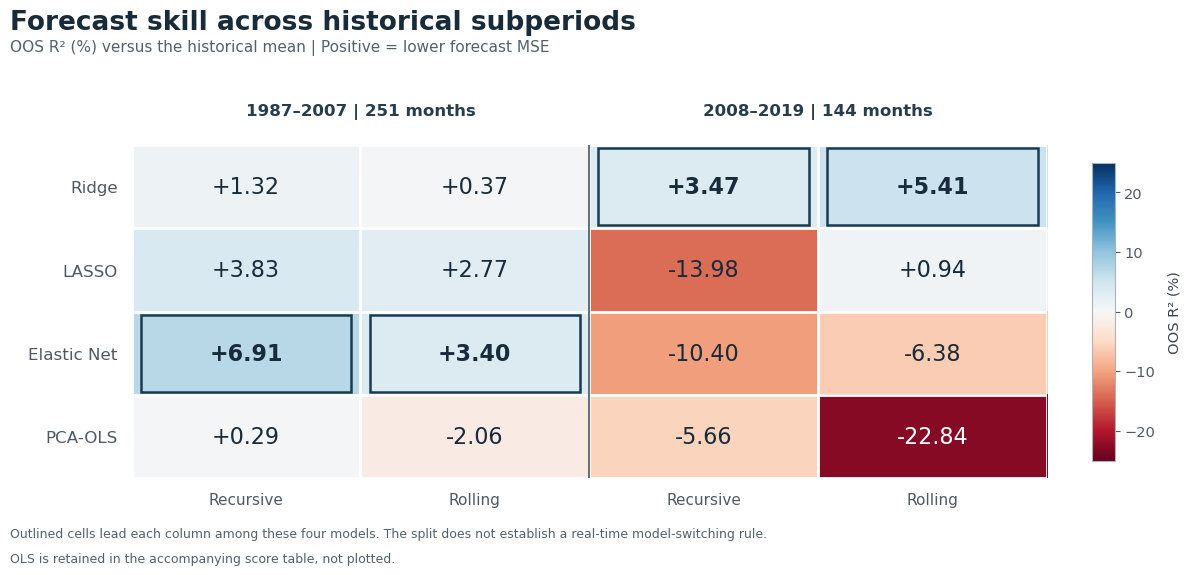

In [8]:
def plot_subperiods(scores):
    columns = [(period, kind) for period in ["1987-2007", "2008-2019"]
               for kind in ["recursive", "rolling"]]
    indexed = scores.set_index(["model", "period", "window"])
    values = np.array([[indexed.loc[(name, period, kind), "oos_r2_pct"]
                        for period, kind in columns] for name in PLOT_MODELS])
    fig, ax = plt.subplots(figsize=(12.8, 5.9))
    fig.subplots_adjust(left=0.15, right=0.865, top=0.755, bottom=0.19)
    fig.suptitle("Forecast skill across historical subperiods", x=0.055, y=0.985,
                 ha="left", fontsize=19, fontweight="bold", color="#172B3A")
    fig.text(0.055, 0.913,
             "OOS R² (%) versus the historical mean | Positive = lower forecast MSE",
             fontsize=11, color="#53616B")
    limit = max(25, float(np.abs(values).max()))
    im = ax.imshow(values, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(4), ["Recursive", "Rolling", "Recursive", "Rolling"], fontsize=11)
    ax.set_yticks(range(4), PLOT_MODELS, fontsize=12)
    ax.tick_params(axis="both", length=0, pad=10)
    ax.text(0.25, 1.09, "1987–2007 | 251 months", transform=ax.transAxes,
            ha="center", fontsize=12, fontweight="bold", color="#263D4D")
    ax.text(0.75, 1.09, "2008–2019 | 144 months", transform=ax.transAxes,
            ha="center", fontsize=12, fontweight="bold", color="#263D4D")
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", length=0)
    ax.axvline(1.5, color="#52636F", linewidth=1.3)
    for row in range(4):
        for column in range(4):
            value = values[row, column]
            ax.text(column, row, f"{value:+.2f}", ha="center", va="center", fontsize=16,
                    fontweight="bold" if row == np.argmax(values[:, column]) else "normal",
                    color="white" if abs(value) > limit * 0.64 else "#172B3A")
    for column in range(4):
        row = int(np.argmax(values[:, column]))
        ax.add_patch(Rectangle((column - 0.46, row - 0.46), 0.92, 0.92,
                               fill=False, edgecolor="#193B50", linewidth=1.8))
    for spine in ax.spines.values():
        spine.set_visible(False)
    color_axis = fig.add_axes([0.9, 0.22, 0.018, 0.505])
    fig.colorbar(im, cax=color_axis).set_label("OOS R² (%)", labelpad=9)
    fig.text(0.055, 0.09,
             "Outlined cells lead each column among these four models. The split does not establish a real-time model-switching rule.",
             fontsize=9, color="#53616B")
    fig.text(0.055, 0.048,
             "OLS is retained in the accompanying score table, not plotted.",
             fontsize=9, color="#53616B")
    fig.savefig(RESULTS / "subperiod_comparison.png", dpi=160)
    plt.show()

plot_subperiods(scores)


Elastic Net led the pre-2008 comparisons (recursive OOS R²: **6.91%**); Ridge led after 2008 (rolling: **5.41%**). Window choice mattered.

These are historical forecasting comparisons, not a validated real-time model-switching strategy. LASSO and Elastic Net may emit convergence warnings.
